In [ ]:
from dask.distributed import Client
client = Client()
client

Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: http://127.0.0.1:8787/status,
Dashboard: http://127.0.0.1:8787/status,Workers: 8
Total threads: 32,Total memory: 35.00 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:34743,Workers: 0
Dashboard: http://127.0.0.1:8787/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:44423,Total threads: 4
Dashboard: http://127.0.0.1:46063/status,Memory: 4.38 GiB
Nanny: tcp://127.0.0.1:42077,


2026-09-29 20:59:08,457 - tornado.application - ERROR - Uncaught exception GET /status/ws (127.0.0.1)
HTTPServerRequest(protocol='http', host='127.0.0.1:8787', method='GET', uri='/status/ws', version='HTTP/1.1', remote_ip='127.0.0.1')
Traceback (most recent call last):
  File "/nird/home/rguilcas/robin-env/lib/python3.12/site-packages/tornado/websocket.py", line 965, in _accept_connection
    open_result = handler.open(*handler.open_args, **handler.open_kwargs)
                  ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/nird/home/rguilcas/robin-env/lib/python3.12/site-packages/tornado/web.py", line 3409, in wrapper
    return method(self, *args, **kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/nird/home/rguilcas/robin-env/lib/python3.12/site-packages/bokeh/server/views/ws.py", line 149, in open
    raise ProtocolError("Token is expired. Configure the app with a larger value for --session-token-expiration if necessary")
bokeh.protocol.exceptions.Protoco

In [1]:
import io
import gcsfs
import xarray as xr
fs = gcsfs.GCSFileSystem(token="anon")

def open_raw(year, month, day, variable):
    path = (f"gcp-public-data-arco-era5/raw/date-variable-single_level/"
            f"{year}/{month:02d}/{day:02d}/{variable}/surface.nc")
    with fs.open(path, "rb") as f:
        return xr.open_dataset(io.BytesIO(f.read()), engine="scipy")

lsm = open_raw(2023, 1, 1, "land_sea_mask")["lsm"].isel(time=0, drop=True)
land = (lsm.sel(latitude=slice(90, 10)) >= 0.5).load()     # True over land


def get_precip_day_NH(year, month, day, lat_max=90, lat_min=10, land_mask=land):
    path = (f"gcp-public-data-arco-era5/raw/date-variable-single_level/"
            f"{year}/{month:02d}/{day:02d}/total_precipitation/surface.nc")
    with fs.open(path, "rb") as f:
        buf = io.BytesIO(f.read())                      # one download of the whole file
    ds = xr.open_dataset(buf, engine="scipy")
    tp = ds["tp"].sel(latitude=slice(lat_max, lat_min))#.where(land_mask)
    if 'valid_time' in tp.coords:
        tp = tp.sum("valid_time", min_count=1) * 1000   # mm/day
    else:
        tp = tp.sum("time", min_count=1) * 1000 
    return tp.load()



In [2]:
from concurrent.futures import ThreadPoolExecutor
import pandas as pd
from tqdm.notebook import tqdm 

def get_day(date):
    tp = get_precip_day_NH(date.year, date.month, date.day)
    return tp.expand_dims(time=[date])   # mask ocean, label the day

all_winters = []
for year in [2023,2024,2025]:
    dates = pd.date_range(f"{year}-09-01", f"{year+1}-02-28", freq="D")
    with ThreadPoolExecutor(max_workers=32) as pool:
        days = list(tqdm(pool.map(get_day, dates), total=len(dates)))
    tp = xr.concat(days, dim="time")
    all_winters.append(tp)

tp = xr.concat(all_winters, dim='time').isel(expver=0)
tp.attrs['unit'] = 'mm/day'
tp.to_netcdf('/nird/datapeak/NS12107K/rguilcas/data/tp_daily_winter_2023-2025_Nh_10_90.nc')

# land.to_netcdf('/nird/datapeak/NS12107K/rguilcas/data/era5_saeland_mask_Nh_30_80.nc')

  0%|          | 0/181 [00:00<?, ?it/s]

  0%|          | 0/181 [00:00<?, ?it/s]

  0%|          | 0/181 [00:00<?, ?it/s]

In [18]:
import numpy as np, xarray as xr

era5 = xr.open_zarr('gs://weatherbench2/datasets/era5/1959-2022-6h-1440x721.zarr',
                    storage_options={'token': 'anon'}).sel(time=slice('1990', '2019'))

tp = era5['total_precipitation_24hr']
mask_land = xr.open_dataarray('/nird/datapeak/NS12107K/rguilcas/data/era5_saeland_mask_Nh_30_80.nc')
tp = tp.where(mask_land == 1)  # mask out the land areas

t = tp.time
keep = t.dt.season.isin(['SON']) & (t.dt.hour == 0)          # pick the hour matching your target window
tp = tp.sel(time=keep)  
climato = tp.quantile([0.9,0.95,0.99],'time').load()*1000
climato.attrs['units'] = 'mm'
climato.attrs['season'] = 'SON'
climato.attrs['period'] = '1990-2019'
climato.to_netcdf('/nird/datapeak/NS12107K/rguilcas/data/ERA5_extreme_precip_climato_SON_1990_2019_NH.nc')

In [17]:
climato.to_netcdf('/nird/datapeak/NS12107K/rguilcas/data/ERA5_extreme_precip_climato_DJF_1990_2019_NH.nc')

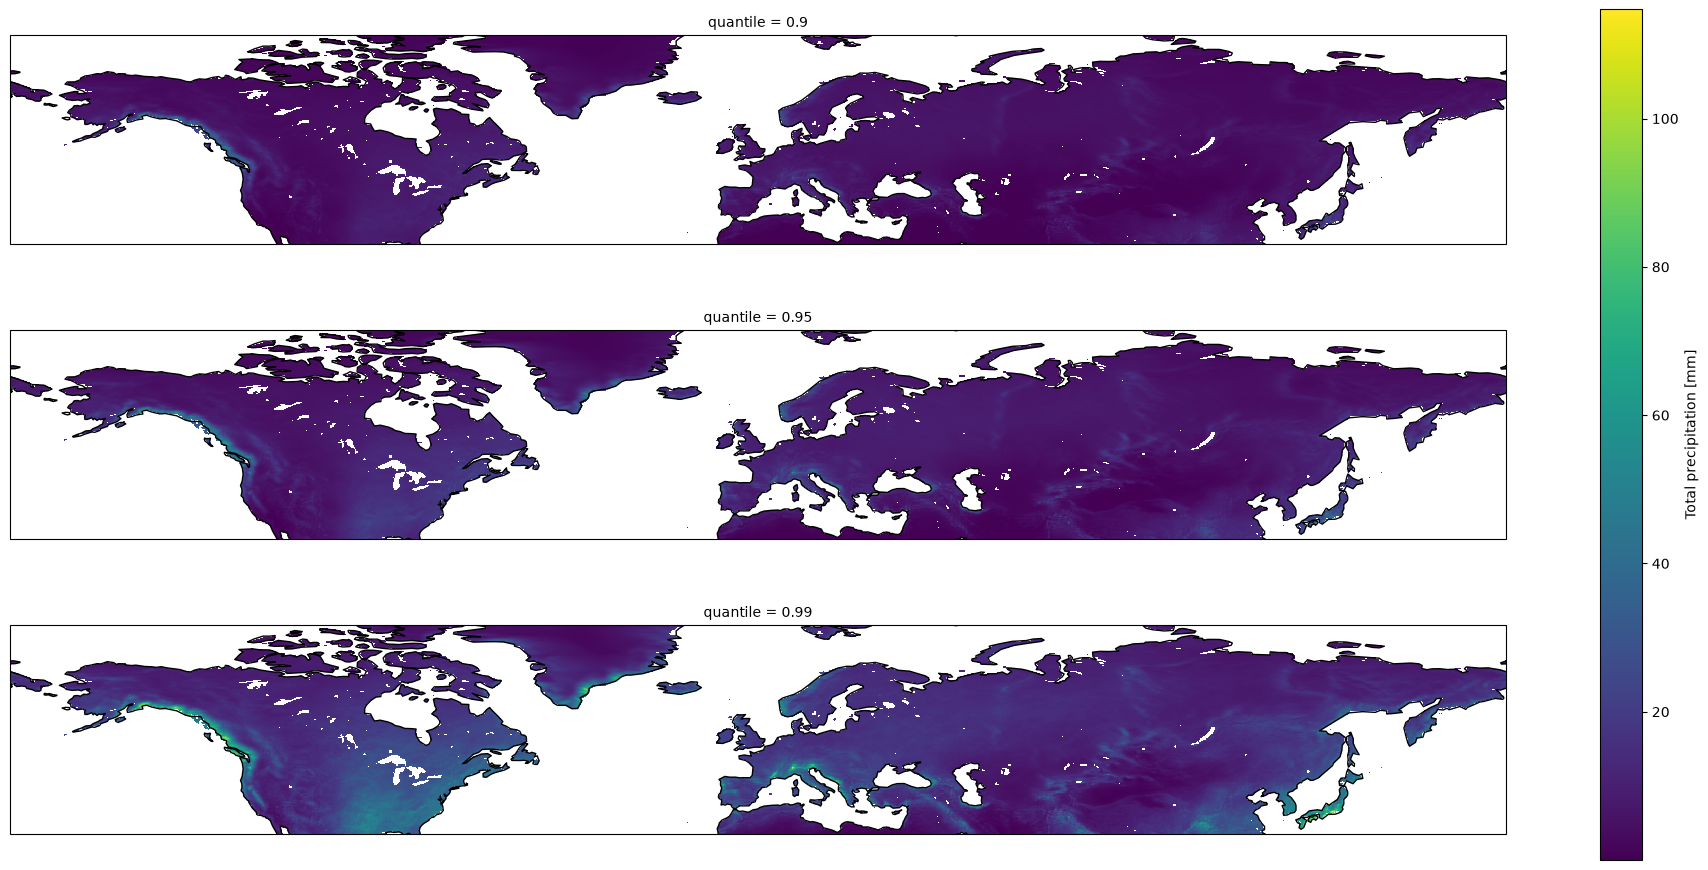

In [19]:
import cartopy.crs as ccrs

plot = climato.plot(subplot_kws = dict(projection=ccrs.PlateCarree()), transform=ccrs.PlateCarree(), size=3, aspect=6, row='quantile')
for ax in plot.axs.flat:
    ax.coastlines()


In [10]:
climato

<xarray.DataArray 'total_precipitation_24hr' (quantile: 3, latitude: 201,
                                              longitude: 1440)> Size: 3MB
array([[[       nan,        nan,        nan, ...,        nan,
                nan,        nan],
        [       nan,        nan,        nan, ...,        nan,
                nan,        nan],
        [       nan,        nan,        nan, ...,        nan,
                nan,        nan],
        ...,
        [0.05899873, 0.06481539, 0.06101746, ..., 0.07093716,
         0.07152567, 0.05577067],
        [0.04460933, 0.04636962, 0.05000625, ..., 0.04629456,
         0.04430013, 0.0381643 ],
        [0.02884734, 0.034374  , 0.03275089, ..., 0.03492013,
         0.02910458, 0.02909862]],

       [[       nan,        nan,        nan, ...,        nan,
                nan,        nan],
        [       nan,        nan,        nan, ...,        nan,
                nan,        nan],
        [       nan,        nan,        nan, ...,        nan,
                nan,        nan],
...
        [0.6633239 , 0.59832287, 0.5833975 , ..., 0.65599096,
         0.65864885, 0.66051406],
        [0.5126655 , 0.5109524 , 0.5539712 , ..., 0.48220935,
         0.519825  , 0.53747576],
        [0.40681317, 0.41107908, 0.38883305, ..., 0.42264593,
         0.39332113, 0.41527665]],

       [[       nan,        nan,        nan, ...,        nan,
                nan,        nan],
        [       nan,        nan,        nan, ...,        nan,
                nan,        nan],
        [       nan,        nan,        nan, ...,        nan,
                nan,        nan],
        ...,
        [4.3633947 , 4.7881103 , 4.672924  , ..., 4.3986044 ,
         4.518901  , 4.22994   ],
        [3.9842594 , 4.4178944 , 4.5144405 , ..., 4.169331  ,
         3.5740192 , 3.7943888 ],
        [3.7363024 , 3.564092  , 3.6547015 , ..., 4.0114117 ,
         3.9319162 , 3.745417  ]]], shape=(3, 201, 1440), dtype=float32)
Coordinates:
  * quantile   (quantile) float64 24B 0.9 0.95 0.99
  * latitude   (latitude) float32 804B 80.0 79.75 79.5 79.25 ... 30.5 30.25 30.0
  * longitude  (longitude) float32 6kB 0.0 0.25 0.5 0.75 ... 359.2 359.5 359.8
Attributes:
    long_name:   Total precipitation
    short_name:  tp
    units:       m

In [ ]:
time_winter = era5.time.loc[dict(time=era5.time.dt.season.isin(['DJF']))]
data_array = era5['total_precipitation_24hr'].sel(time=time_winter).coarsen(time=4).mean()

climato = data_array.quantile(0.95,'time').load()

In [ ]:
# import xarray as xr

# clim = xr.open_zarr(
#     'gs://weatherbench2/datasets/era5-hourly-climatology/1990-2019_6h_1440x721.zarr',
#     storage_options={'token': 'anon'},
# )
# tp = clim['total_precipitation_24hr'].sortby('latitude') * 1000   # m -> mm

# # e.g. the Texas Hill Country box on 4 July (day of year 185), 12 UTC
# box = tp.sel(dayofyear=185, hour=12,
#              latitude=slice(30, 80))


In [ ]:

# tp = (era5['total_precipitation_24hr'].sortby('latitude')
#       .sel(time=slice('1990', '2019'), latitude=slice(29, 31), longitude=slice(260, 262)))
# tp = tp.sel(time=tp.time.dt.hour == 12) * 1000          # one 24 h total per day, in mm
# tp_box = tp.mean(['latitude', 'longitude']).compute()   # area mean, matching your target

# # pool ±15 days around the date of interest (4 July ≈ day 185)
# doy = tp_box.time.dt.dayofyear
# win = tp_box.where(np.abs((doy - 185 + 182) % 365 - 182) <= 15, drop=True)
# print('p95 all days:', float(win.quantile(0.95)),
#       '| p95 wet days (≥1 mm):', float(win.where(win >= 1).quantile(0.95)))

In [15]:
era5.time.dt.season.isin(['DJF','SON'])

<xarray.DataArray 'season' (time: 92044)> Size: 92kB
array([ True,  True,  True, ...,  True,  True,  True], shape=(92044,))
Coordinates:
  * time     (time) datetime64[ns] 736kB 1959-01-01 ... 2021-12-31T18:00:00

In [17]:
era5['total_precipitation_24hr'].loc[dict(time=era5.time.dt.season.isin(['DJF','SON']))].groupby('season').quantile(0.95,'time')
#.where(mask_land).quantile(0.95, 'time')

KeyError: 'season'